# Two-photon: feedback responses

Figures 6A (bottom), 6B, 6C, 6E and S14A.

**Reads** (`data/2p/`): `df_all_by_epoch.pkl` (raw fluorescence),
`df_all_by_trial_normalized.pkl`, and `data_runs_Unnormalized.pkl` /
`data_runs_Feedback_fixed.pkl` (written by `2p_0_preprocessing`).

**Writes**: figures under `results/2P/` with `SAVE_FIGS`; nothing under
`data/`.

Figures 6B and S14A are measured against the neurons active during sampling.
That selection is recomputed here from the raw traces, exactly as
`2p_0_preprocessing` computes it (`twop/samplingreliability.py`), so this
notebook needs nothing that notebook writes besides `data/2p`; its per-neuron
figures are written there, not again here.

# Run this to enable loading from relative paths

In [ ]:
%load_ext autoreload
%autoreload 2
if "PKG" not in globals():
  import importlib, sys, pathlib # https://stackoverflow.com/a/50395128/11996983
  PKG = %pwd
  PKG = pathlib.Path(PKG)
  root_parent_level = 1
  root = PKG
  full_pkg = f"{root.name}"
  for _ in range(root_parent_level):
    root = root.parent
    full_pkg = f"{root.name}.{full_pkg}"
    MODULE_PATH = f"{root}{pathlib.os.path.sep}__init__.py"
    MODULE_NAME = f"{root.name}"
    spec = importlib.util.spec_from_file_location(MODULE_NAME, MODULE_PATH)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
  __package__ = full_pkg


# Save plots with no embeded fonts

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# Parameters

In [ ]:
# Papermill parameters -- code/run_notebooks.py overrides these.
# Everything is off by default, so running the notebook writes nothing.
SAVE_FIGS = False           # write figures under results/
SAVE_DATA = False           # rewrite cached intermediate data under data/
PAPER_FIGURES_ONLY = False  # skip per-subject / per-session figures

In [ ]:
import pathlib

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from .common.definitions import BrainRegion

PVAL = 0.05

RESULTS_DIR = r"../results/2P"
fig_save_prefix = "../results/2P/"
pathlib.Path(fig_save_prefix).mkdir(exist_ok=True)

# Neurons active during sampling, from the raw traces

In [ ]:
from .twop.dataload import loadEpochTraces
from .twop.samplingreliability import (alignSamplingFrames, collectReliability,
                                       makeNormedAll)
from .twop.tracereliability import (DecideNeurons, StdDistCollector,
                                    loopSessionsExampleNeurons)

df_all_by_epoch = loadEpochTraces()
unnormed_sampling_df, normed_sampling_df, sampling_stats_df = \
    alignSamplingFrames(df_all_by_epoch)
# Every epoch of every trial, the feedback epochs cut to 0.3 s
normed_all_df = makeNormedAll(df_all_by_epoch.copy())

np.seterr(all='raise')
_decide_neurons = DecideNeurons(smooth_sigma=1)
# The same runs as 2p_0_preprocessing; their figures are written there.
all_res_normed_dict, all_res_normed_df = collectReliability(
    normed_sampling_df, _decide_neurons, pdf_str="max_firing_all_normed",
    save_figs=False)
all_res_unnormed_dict, all_res_unnormed_df = collectReliability(
    unnormed_sampling_df, _decide_neurons, pdf_str="max_firing_all_unnormed",
    save_figs=False)

## Feedback trace reliability

In [ ]:
# The feedback traces start on a decay, so it is flattened before the
# spread is measured -- see disable_first_neg_deflect in tracereliability.
_feedback_collector = StdDistCollector(_decide_neurons,
                                       disable_first_neg_deflect=True)
normed_feedback_df = normed_all_df[normed_all_df.epoch.isin(["Reward", "Punishment"])].copy()
loopSessionsExampleNeurons(normed_feedback_df, random_fraction=1, seed=1,
                           pdf_str="max_firing_all_unnormed",
                           processFn=_feedback_collector.track,
                           save_figs=SAVE_FIGS and not PAPER_FIGURES_ONLY, fig_save_prefix=fig_save_prefix)
all_res_cut_feedback_dict = _feedback_collector.res_dict
all_res_cut_feedback_df = _feedback_collector.frame()

In [ ]:
from .twop.dataload import dataPath
from .util.portablepickle import savePortable

SAVE_CUT_FFEDBACK = False
if SAVE_CUT_FFEDBACK:
    _accepted_sampling_traces = all_res_unnormed_df.loc[all_res_unnormed_df.prcnt_valid > 5, "trace_id"]
    save_df = all_res_cut_feedback_df[all_res_cut_feedback_df.trace_id.isin(_accepted_sampling_traces)]
    _FP = dataPath("traces_cut_feedback_df.pkl")
    savePortable(save_df, _FP)
    print(f"Saved cut feedback df to {_FP}")

## Feedback percentage

In [ ]:
import matplotlib.pyplot as plt
from .common.clr import BrainRegion as BRClr

def plotFeedbackExamples(df, df_ref, df_stats):
    _PRCNT_VALID = 5

    accepted_dict = {"BrainRegion": [], "ShortName":[], "trace_id":[], "total":[],
                        "accepted": []}
    for br, br_df in df.groupby("BrainRegion"):
        br_str = str(BrainRegion(br)).split("_")[0]
        for sess, sess_df in br_df.groupby("ShortName"):
            for _, row in sess_df.iterrows():
                long_trace_id = row.trace_id
                trace_id = int(row.trace_id.rsplit("_", 1)[1])
                long_trace_id = f"{sess}_{trace_id}"
                ref_trace = df_ref[df_ref.trace_id == long_trace_id]
                assert len(ref_trace) == 1, display(row) or f"Trace ID {long_trace_id} not found in reference DataFrame"
                ref_trace = ref_trace.iloc[0]
                ref_threshold_std = ref_trace.std_threshold
                # ref stats
                stats_row = df_stats[df_stats.ShortName == sess].iloc[0]
                trace_stats = stats_row["neuronal_stats"][trace_id]
                trace_mean = trace_stats["mean"]
                trace_std = trace_stats["std"]

                count_accepted = 0
                count_total = 0
                for arr in [row.whole_trace, row.invalid_whole_trace]:
                    for trace in arr:
                        trace = (trace - trace_mean) / trace_std
                        is_accepted = trace.std() >= ref_threshold_std
                        count_total += 1
                        if is_accepted:
                            count_accepted += 1

                accepted_dict["BrainRegion"].append(br_str)
                accepted_dict["ShortName"].append(sess)
                accepted_dict["trace_id"].append(trace_id)
                accepted_dict["total"].append(count_total)
                accepted_dict["accepted"].append(count_accepted)


    accepted_df = pd.DataFrame(accepted_dict)
    accepted_df["prcnt_valid"] = (accepted_df.accepted / accepted_df.total) * 100
    assert accepted_df.prcnt_valid.max() <= 100, \
        f"Percent valid {accepted_df.prcnt_valid.max()} > 100%"
    fig, ax = plt.subplots()
    fig.set_size_inches(15, 5)
    for br_str, br_df in accepted_df.groupby("BrainRegion"):
        prcnt_valid = (br_df.prcnt_valid > _PRCNT_VALID).mean() * 100
        print(f"{br_str} - @_PRCNT_VALID >=: {_PRCNT_VALID} = {prcnt_valid:.3g}%")

        prcnt_valid_sorted = br_df.prcnt_valid.sort_values()
        # Plot CDF
        y = 1 - (prcnt_valid_sorted.reset_index(drop=True).index / len(prcnt_valid_sorted))
        x = prcnt_valid_sorted.values
        ax.plot(x, y, color=BRClr[br_str + "_Bi"],
                lw=2, label='CDF')

    ax.spines[["left", "right", "top"]].set_visible(False)
    ax.set_title(f"Brain Region: {br_str} - Percent Valid Traces")
    ax.set_xlabel("Percent Valid Traces")
    ax.set_ylabel("Count")
    ax.axvline(_PRCNT_VALID, ls="--", c="red", label=f"Threshold: {_PRCNT_VALID}%")
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_idx = 1
    x_labels = []
    for br_str, br_df in accepted_df.groupby("BrainRegion"):
        prcnt_valid_sess = br_df.groupby("ShortName").apply(
                  lambda grp_df: 100*(grp_df.prcnt_valid > _PRCNT_VALID).mean())
        prcnt_valid_sess_mean = prcnt_valid_sess.mean()
        prcnt_valid_sess_sem = prcnt_valid_sess.std()
        x_labels.append(br_str)
        clr = BRClr[br_str + "_Bi"]
        ax.boxplot(prcnt_valid_sess, positions=[bar_idx], widths=0.5,
                   patch_artist=True, showfliers=True,
                   boxprops=dict(facecolor=clr, color=clr),
                   medianprops=dict(color='k'),
                   whiskerprops=dict(color=clr),
                   capprops=dict(color=clr),
                   flierprops=dict(markerfacecolor=clr, marker='o', markersize=5))
        bar_idx -= 1
    ax.set_xticks(np.arange(len(x_labels)))
    ax.set_xticklabels(x_labels)
    ax.set_title(f"Percent Valid Traces per Session - Threshold: {_PRCNT_VALID}%")
    ax.set_ylabel("Percent Valid Traces")
    ax.set_xlabel("Brain Region")
    ax.spines[["right", "top"]].set_visible(False)
    plt.show()
    return accepted_df[accepted_df.prcnt_valid > _PRCNT_VALID]




accepted_sampling_traces = all_res_unnormed_df.loc[all_res_unnormed_df.prcnt_valid > 5, "trace_id"]
src_df = all_res_cut_feedback_df
above_thresh_feedback_df = plotFeedbackExamples(src_df[src_df.trace_id.isin(accepted_sampling_traces)],
                                                all_res_unnormed_df, sampling_stats_df)

ALM - @_PRCNT_VALID >=: 5 = 25.9%
M2 - @_PRCNT_VALID >=: 5 = 52%


## Feedback percentage and distribution — Figure 6B

In [ ]:
_PRCNT_VALID = 5
accepted_sampling_unnormed_df = all_res_unnormed_df[all_res_unnormed_df.prcnt_valid > _PRCNT_VALID]
accepted_sampling_normed_df = all_res_normed_df[all_res_normed_df.trace_id.isin(accepted_sampling_unnormed_df.trace_id)]

Max firing position: 33


,BrainRegion,ShortName,trace_id,total,accepted,firing_pos,prcnt_valid,rel_firing_pos,pos
0,ALM,GP4_23_s6_L50_D250_ALM,0,224,5,18.266667,2.232143,55.353535,1
1,ALM,GP4_23_s6_L50_D250_ALM,2,224,2,2.064516,0.892857,6.256109,0
2,ALM,GP4_23_s6_L50_D250_ALM,3,224,1,2.666667,0.446429,8.080808,0
3,ALM,GP4_23_s6_L50_D250_ALM,4,224,13,20.133333,5.803571,61.010101,1
4,ALM,GP4_23_s6_L50_D250_ALM,5,224,46,25.232143,20.535714,76.461039,2
...,...,...,...,...,...,...,...,...,...
1438,M2,GP4_85_s3_L70_D250_mm2,235,218,55,26.029762,25.229358,78.878066,2
1439,M2,GP4_85_s3_L70_D250_mm2,278,218,12,20.888889,5.504587,63.299663,1
1440,M2,GP4_85_s3_L70_D250_mm2,379,218,7,11.545455,3.211009,34.986226,1
1441,M2,GP4_85_s3_L70_D250_mm2,391,218,35,30.426667,16.055046,92.202020,2


ALM - @_PRCNT_VALID >=: 5 = 25.9%
M2 - @_PRCNT_VALID >=: 5 = 52%


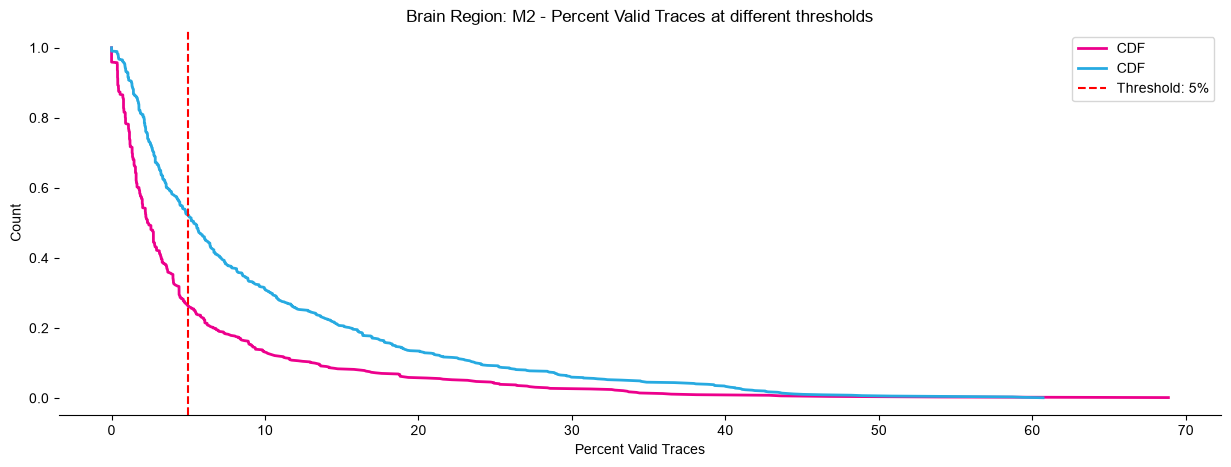

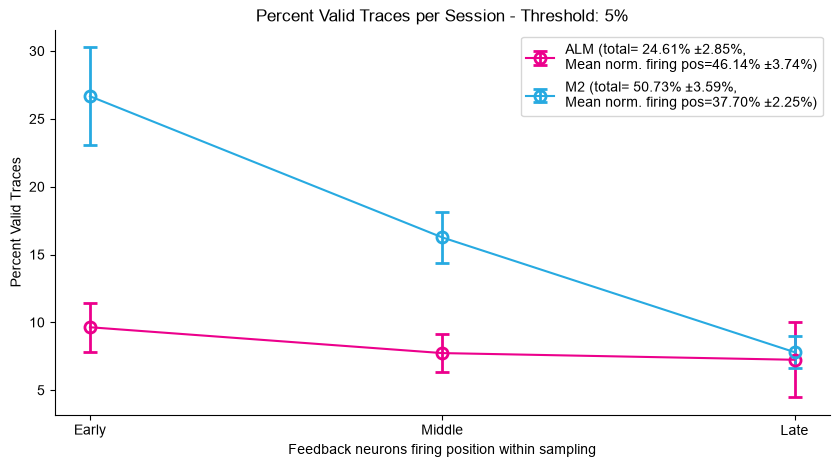

In [ ]:
from .common.clr import BrainRegion as BRClr
import matplotlib.pyplot as plt
from scipy import stats

def plotFeedbackDist(df_feedback, df_accepted, df_stats,
                     df_accepted_normed_pos, save_figs=False):
    accepted_dict = {"BrainRegion": [], "ShortName":[], "trace_id":[], "total":[],
                     "accepted": [], "firing_pos":[]}
    max_firing_pos = -1

    for br, br_df in df_feedback.groupby("BrainRegion"):    
        br_str = str(BrainRegion(br)).split("_")[0]
        for sess, sess_df in br_df.groupby("ShortName"):
            for _, row in sess_df.iterrows():
                long_trace_id = row.trace_id
                trace_id = int(row.trace_id.rsplit("_", 1)[1])
                long_trace_id = f"{sess}_{trace_id}"
                ref_trace = df_accepted[df_accepted.trace_id == long_trace_id]
                assert len(ref_trace) == 1, display(row) or f"Trace ID {long_trace_id} not found in reference DataFrame"
                
                ref_trace = ref_trace.iloc[0]
                ref_threshold_std = ref_trace.std_threshold
                # ref stats
                stats_row = df_stats[df_stats.ShortName == sess].iloc[0]
                trace_stats = stats_row["neuronal_stats"][trace_id]
                trace_mean = trace_stats["mean"]
                trace_std = trace_stats["std"]

                count_accepted = 0
                count_total = 0
                for arr in [row.whole_trace, row.invalid_whole_trace]:
                    for trace in arr:
                        trace = (trace - trace_mean) / trace_std
                        is_accepted = trace.std() >= ref_threshold_std
                        count_total += 1
                        if is_accepted:
                            count_accepted += 1
                
                normed_trace_row = df_accepted_normed_pos[df_accepted_normed_pos.trace_id == long_trace_id]
                assert len(normed_trace_row) == 1, display(row) or f"Trace ID {long_trace_id} not found in normed DataFrame"
                normed_trace_row = normed_trace_row.iloc[0]

                fire_pos = normed_trace_row.max_idxs.mean() if len(normed_trace_row.max_idxs) else np.nan
                if max_firing_pos == -1:
                    max_firing_pos = normed_trace_row.whole_trace.shape[-1]                

                accepted_dict["BrainRegion"].append(br_str)
                accepted_dict["ShortName"].append(sess)
                accepted_dict["trace_id"].append(trace_id)
                accepted_dict["total"].append(count_total)
                accepted_dict["accepted"].append(count_accepted)
                accepted_dict["firing_pos"].append(fire_pos)

    print("Max firing position:", max_firing_pos)

    accepted_df = pd.DataFrame(accepted_dict)
    accepted_df["prcnt_valid"] = (accepted_df.accepted / accepted_df.total) * 100
    accepted_df["rel_firing_pos"] = accepted_df.firing_pos / max_firing_pos * 100
    accepted_df["pos"] = 0 #"Early"
    accepted_df.loc[(100/3 < accepted_df.rel_firing_pos) &
                    (accepted_df.rel_firing_pos < 100*2/3), "pos"] = 1 # "Middle"
    accepted_df.loc[100*2/3 < accepted_df.rel_firing_pos, "pos"] = 2 #"Late"
    # Assign each session the number of traces in it
    display(accepted_df)
    assert accepted_df.prcnt_valid.max() <= 100, \
        f"Percent valid {accepted_df.prcnt_valid.max()} > 100%"
    fig, ax = plt.subplots()
    fig.set_size_inches(15, 5)
    for br_str, br_df in accepted_df.groupby("BrainRegion"):
        prcnt_valid = (br_df.prcnt_valid > _PRCNT_VALID).mean() * 100
        print(f"{br_str} - @_PRCNT_VALID >=: {_PRCNT_VALID} = {prcnt_valid:.3g}%")

        # fig, ax = plt.subplots()
        # fig.set_size_inches(15, 5)
        # ax.hist(br_df.prcnt_valid, bins=np.arange(0, 102, 2), color='gray',
        #         alpha=0.5)
        prcnt_valid_sorted = br_df.prcnt_valid.sort_values()
        # print(prcnt_valid_sorted)
        # Plot CDF
        y = 1 - (prcnt_valid_sorted.reset_index(drop=True).index / len(prcnt_valid_sorted))
        # y = 100*y/len(prcnt_valid_sorted)
        x = prcnt_valid_sorted.values
        ax.plot(x, y, color=BRClr[br_str + "_Bi"],
                lw=2, label='CDF')

    ax.spines[["left", "right", "top"]].set_visible(False)
    ax.set_title(f"Brain Region: {br_str} - Percent Valid Traces at different thresholds")
    ax.set_xlabel("Percent Valid Traces")
    ax.set_ylabel("Count")
    ax.axvline(_PRCNT_VALID, ls="--", c="red", label=f"Threshold: {_PRCNT_VALID}%")
    ax.legend()
    if save_figs:
        fig.savefig(f"{RESULTS_DIR}/feedback_neurons_valid_traces_thresholds.svg",
                    bbox_inches='tight', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5))
    x_labels = ["Early", "Middle", "Late"]
    for br_str, br_df in accepted_df.groupby("BrainRegion"):
        clr = BRClr[br_str + "_Bi"]
        ys = []
        sess_counts = {sess: len(sess_df) 
                       for sess, sess_df in br_df.groupby("ShortName")}
        
        def calcDfPrcntValid(sub_df ):
            prcnt_valid_sess = sub_df.groupby("ShortName").apply(
                      lambda grp_df: 100*(grp_df.prcnt_valid > _PRCNT_VALID).sum() / 
                                     sess_counts[grp_df.ShortName.iloc[0]])
            return prcnt_valid_sess
        
        for pos in [0, 1, 2]:
            pos_df = br_df[br_df.pos == pos]
            pos_sess_mean = calcDfPrcntValid(pos_df)
            ys.append(pos_sess_mean)
            
        # print("Ys:", ys)
        ys = np.array(ys)
        ys_mean = ys.mean(axis=1)
        ys_sem = stats.sem(ys, axis=1)
        xs = [0, 1, 2]
        ys_total = calcDfPrcntValid(br_df)
        ys_total_mean = ys_total.mean()
        ys_total_sem = stats.sem(ys_total)
        max_firing_pos = br_df.groupby("ShortName").apply(
            lambda grp_df: grp_df[grp_df.prcnt_valid > _PRCNT_VALID].rel_firing_pos.mean())
        max_firing_pos_mean = max_firing_pos.mean()
        max_firing_pos_sem = stats.sem(max_firing_pos)
        ax.errorbar(xs, ys_mean, yerr=ys_sem, color=clr, 
                    marker="o", markerfacecolor='none',
                    capsize=5, elinewidth=2, markeredgewidth=2, markersize=8,
                    label=f"{br_str} (total= {ys_total_mean:.2f}% ±{ys_total_sem:.2f}%,\n"
                          f"Mean norm. firing pos={max_firing_pos_mean:.2f}% ±{max_firing_pos_sem:.2f}%)")

    ax.set_xticks(np.arange(len(x_labels)))
    ax.set_xticklabels(x_labels)
    ax.set_title(f"Percent Valid Traces per Session - Threshold: {_PRCNT_VALID}%")
    ax.set_ylabel("Percent Valid Traces")
    ax.set_xlabel("Feedback neurons firing position within sampling")
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend()
    if save_figs:
        fig.savefig(f"{RESULTS_DIR}/feedback_neurons_dist_andfiring_pos.svg",
                    bbox_inches='tight', dpi=300)
    plt.show()

    return accepted_df[accepted_df.prcnt_valid > _PRCNT_VALID]


above_thresh_feedback_df = plotFeedbackDist(all_res_cut_feedback_df[all_res_cut_feedback_df.trace_id.isin(accepted_sampling_unnormed_df.trace_id)], 
                                            accepted_sampling_unnormed_df,
                                            sampling_stats_df, accepted_sampling_normed_df,
                                            save_figs=SAVE_FIGS)

In [ ]:
above_thresh_feedback_df

,BrainRegion,ShortName,trace_id,total,accepted,firing_pos,prcnt_valid,rel_firing_pos,pos
3,ALM,GP4_23_s6_L50_D250_ALM,4,224,13,20.133333,5.803571,61.010101,1
4,ALM,GP4_23_s6_L50_D250_ALM,5,224,46,25.232143,20.535714,76.461039,2
5,ALM,GP4_23_s6_L50_D250_ALM,6,224,18,7.417582,8.035714,22.477522,0
6,ALM,GP4_23_s6_L50_D250_ALM,8,224,21,8.391304,9.375000,25.428195,0
9,ALM,GP4_23_s6_L50_D250_ALM,11,224,19,7.142857,8.482143,21.645022,0
...,...,...,...,...,...,...,...,...,...
1437,M2,GP4_85_s3_L70_D250_mm2,223,218,14,1.560000,6.422018,4.727273,0
1438,M2,GP4_85_s3_L70_D250_mm2,235,218,55,26.029762,25.229358,78.878066,2
1439,M2,GP4_85_s3_L70_D250_mm2,278,218,12,20.888889,5.504587,63.299663,1
1441,M2,GP4_85_s3_L70_D250_mm2,391,218,35,30.426667,16.055046,92.202020,2


## Feedback correlation with next trial — Figure S14A

In [ ]:
from tqdm.auto import tqdm
def prepeareDF(df_feedback, df_sampling, accepted_sampling_unnormed_df):
    df_feedback = df_feedback.copy()
    df_feedback.loc[df_feedback.epoch.isin(["Reward", "Punishment"]), "epoch"] = "Feedback"
    df_feedback["NextTrialNumber"] = (df_feedback["TrialNumber"] + 1).astype(int)

    res_dict = {"BrainRegion": [], "ShortName": [], "TrialNumber": [], 
                "trace_id": [], "long_trace_id": [],
                "FiringPos":[], "FiringPosRel": [],
                "FeedbackTrace":[], "FeedbackTraceMax": [],
                "NextSamplingTrace": [], "NextSampleTraceMax": [],}
    
    df_feedback["NextTrialNumber"] = df_feedback["TrialNumber"] + 1
    common_cols = ["ShortName", "TrialNumber", "traces_sets", "trace_start_idx", "trace_end_idx"]
    df_merged = pd.merge(df_feedback[["BrainRegion", "NextTrialNumber"] + common_cols], 
                         df_sampling[common_cols],
                         left_on=["ShortName", "NextTrialNumber"],
                         right_on=["ShortName", "TrialNumber"],
                         suffixes=("", "_sampling"),
                         how="left")
    df_merged = df_merged[df_merged.TrialNumber_sampling.notnull()]
    df_merged["trace_start_idx_sampling"] = df_merged["trace_start_idx_sampling"].astype(int)
    df_merged["trace_end_idx_sampling"] = df_merged["trace_end_idx_sampling"].astype(int)

    for (br, sess), sess_df in tqdm(df_merged.groupby(["BrainRegion", "ShortName"]),
                                    desc="Preparing Feedback Traces DataFrame",):
        br_str = str(BrainRegion(br)).split("_")[0]
        sess_accepted_sampling = set(accepted_sampling_unnormed_df[
            accepted_sampling_unnormed_df.ShortName == sess].trace_id.values)
        for _, row in sess_df.iterrows():
            cur_traces_sets = row.traces_sets["neuronal"]
            cur_start_idx = row.trace_start_idx
            cur_end_idx = row.trace_end_idx
            next_traces_sets = row.traces_sets_sampling["neuronal"]
            next_start_idx = row.trace_start_idx_sampling
            next_end_idx = row.trace_end_idx_sampling
            for trace_id, trace in cur_traces_sets.items():
                long_trace_id = f"{sess}_{trace_id}"
                if long_trace_id not in sess_accepted_sampling:
                    continue
                
                cur_trace = trace[cur_start_idx:cur_end_idx+1]
                next_trace = next_traces_sets[trace_id][next_start_idx:next_end_idx+1]
                max_firing_pos = np.argmax(next_trace)
                next_trace_max = next_trace[max_firing_pos]
                res_dict["BrainRegion"].append(br_str)
                res_dict["ShortName"].append(sess)
                res_dict["TrialNumber"].append(row.TrialNumber)
                res_dict["trace_id"].append(trace_id)
                res_dict["long_trace_id"].append(long_trace_id)
                res_dict["FeedbackTrace"].append(cur_trace.copy())
                res_dict["FeedbackTraceMax"].append(cur_trace.max())
                res_dict["NextSamplingTrace"].append(next_trace.copy())
                res_dict["NextSampleTraceMax"].append(next_trace_max)
                res_dict["FiringPos"].append(max_firing_pos)
                res_dict["FiringPosRel"].append(100*max_firing_pos / len(next_trace))

    
    res_df = pd.DataFrame(res_dict)
    assert res_df["NextSamplingTrace"].apply(len).nunique() == 1, \
                    f"NextSamplingTrace lengths are not equal - {res_df['NextSamplingTrace'].apply(len).unique()}"
    return res_df

cur_feedback_next_sampling_df = prepeareDF(normed_all_df[normed_all_df.epoch.isin(["Reward", "Punishment"])],
                                           normed_sampling_df,
                                           accepted_sampling_unnormed_df)
cur_feedback_next_sampling_df

Preparing Feedback Traces DataFrame:   0%|          | 0/23 [00:00<?, ?it/s]

,BrainRegion,ShortName,TrialNumber,trace_id,long_trace_id,FiringPos,FiringPosRel,FeedbackTrace,FeedbackTraceMax,NextSamplingTrace,NextSampleTraceMax
0,ALM,GP4_23_s6_L50_D250_ALM,167,0,GP4_23_s6_L50_D250_ALM_0,11,33.333333,"[471.9137, 537.2516, 873.4656, 922.5907, 534.9...",922.590698,"[-0.06780355, -0.08496408, -0.10216399, -0.508...",1.595292
1,ALM,GP4_23_s6_L50_D250_ALM,167,2,GP4_23_s6_L50_D250_ALM_2,11,33.333333,"[882.922, 420.35327, 364.50098, 393.72058, 889...",889.535889,"[-1.0526334, -0.12448963, -0.28732786, -0.8583...",0.593372
2,ALM,GP4_23_s6_L50_D250_ALM,167,3,GP4_23_s6_L50_D250_ALM_3,6,18.181818,"[902.4972, 898.6144, 629.1488, 243.89331, 383....",902.497192,"[-0.28690386, -0.32879943, 1.6126953, 0.311361...",1.957472
3,ALM,GP4_23_s6_L50_D250_ALM,167,4,GP4_23_s6_L50_D250_ALM_4,14,42.424242,"[3533.1013, 2893.642, 2753.7178, 3010.627, 302...",3533.101318,"[-1.0699577, -0.01596374, -0.38936627, -1.1101...",1.593667
4,ALM,GP4_23_s6_L50_D250_ALM,167,5,GP4_23_s6_L50_D250_ALM_5,17,51.515152,"[1784.0723, 1631.2278, 1367.0459, 1578.7317, 1...",1855.085938,"[1.1054333, 1.2955873, 1.1066569, 1.3214297, 1...",4.431708
...,...,...,...,...,...,...,...,...,...,...,...
335283,M2,GP4_85_s3_L70_D250_mm2,307,235,GP4_85_s3_L70_D250_mm2_235,27,81.818182,"[2295.7168, 2728.4297, 2583.1245, 1319.2695, 1...",2728.429688,"[-0.7946559, -1.0668049, -1.1477958, -0.826919...",-0.095887
335284,M2,GP4_85_s3_L70_D250_mm2,307,278,GP4_85_s3_L70_D250_mm2_278,26,78.787879,"[811.03284, 835.8458, 990.0447, 771.77954, 702...",1125.754150,"[-1.0080239, -0.6593396, -1.4379921, 0.2678157...",0.362458
335285,M2,GP4_85_s3_L70_D250_mm2,307,379,GP4_85_s3_L70_D250_mm2_379,24,72.727273,"[446.54993, 423.68933, 424.31555, 330.7284, 28...",623.608887,"[-1.0647919, -1.9616328, -0.10932224, -1.36762...",0.426794
335286,M2,GP4_85_s3_L70_D250_mm2,307,391,GP4_85_s3_L70_D250_mm2_391,28,84.848485,"[2881.744, 2266.0664, 2122.1016, 2782.1064, 25...",2881.743896,"[-0.5463443, -0.58647996, -0.44215962, -0.5246...",2.163683


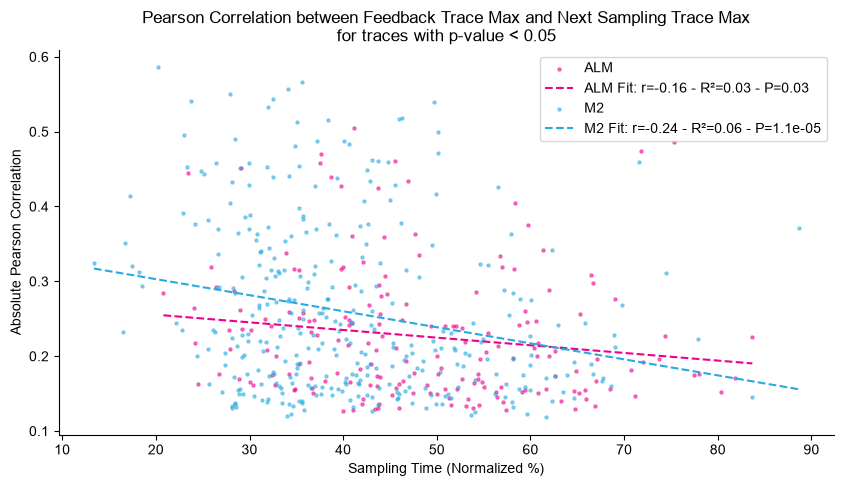

In [ ]:
from .common.clr import BrainRegion as BRClr
import matplotlib.pyplot as plt
from scipy import stats

def corrNextTrial(df, save_figs=False):
    res_dict = {"BrainRegion": [], "ShortName": [], "TraceID":[], "MeanFiringPos": [],
                "corr": [], "pval": []}
    for br, br_df in df.groupby("BrainRegion"):
        for sess, sess_df in br_df.groupby("ShortName"):
            for trace_id, trace_df in sess_df.groupby("trace_id"):
                if len(trace_df) < 2:
                    continue
                # print("Trace ID:", trace_id, " - len:", len(trace_df))
                x = trace_df.FeedbackTraceMax.values
                y = trace_df.NextSampleTraceMax.values
                corr, pval = stats.pearsonr(x, y)
                mean_firing_pos = trace_df.FiringPosRel.mean()
                res_dict["BrainRegion"].append(br)
                res_dict["ShortName"].append(sess)
                res_dict["TraceID"].append(trace_id)
                res_dict["MeanFiringPos"].append(mean_firing_pos)
                res_dict["corr"].append(corr)
                res_dict["pval"].append(pval)

    res_df = pd.DataFrame(res_dict)

    fig, ax = plt.subplots(figsize=(10, 5))
    for br, br_df in res_df.groupby("BrainRegion"):
        br_clr = BRClr[br + "_Bi"]
        # STEP_PRCNT = 10
        # bins = np.arange(0, 100 + STEP_PRCNT, step=STEP_PRCNT)
        br_df = br_df.sort_values("MeanFiringPos")
        br_df = br_df[br_df.pval < 0.05]  # Filter by p-value
        br_df = br_df.copy()
        br_df["corrAbs"] = br_df["corr"].abs()
        COL = "corrAbs"
        ax.scatter(br_df.MeanFiringPos.values, br_df[COL].values, label=br, 
                   color=br_clr, alpha=0.5, s=5)
        # Fit a line
        slope, intercept, r_value, p_value, std_err = stats.linregress(
                                 br_df.MeanFiringPos.values, br_df[COL].values)
        x_fit = np.linspace(br_df.MeanFiringPos.min(), br_df.MeanFiringPos.max(), 100)
        y_fit = slope * x_fit + intercept
        ax.plot(x_fit, y_fit, color=br_clr, ls='--', label=f"{br} Fit: r={r_value:.2f} - R²={r_value**2:.2f} - P={p_value:.2g}")
                   
    ax.set_xlabel("Sampling Time (Normalized %)")
    ax.set_title("Pearson Correlation between Feedback Trace Max and Next Sampling Trace Max\n"
                 "for traces with p-value < 0.05")
    ax.set_ylabel("Absolute Pearson Correlation")
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend()
    if save_figs:
        fig.savefig(f"{RESULTS_DIR}/corr_feedback_next_sampling.svg")
    plt.show()

corrNextTrial(cur_feedback_next_sampling_df, save_figs=SAVE_FIGS)

# Feedback heatmaps — Figure 6A (bottom)

In [ ]:
from .twop import sessionheatmaps as sh
from .twop.dataload import loadTrialNormalized
from .twop.plottracesavg import Combinations

df_all_by_trial_normalized = loadTrialNormalized()

align_feedback_time = 0.5 # sec
limit_end_epoch = True
feedback_common_kwargs = sh.makeContext(
    cache_extra_prefix=f"feedback_normalized_align_feedback_{align_feedback_time}s_limit_end_{limit_end_epoch}",
    fig_save_prefix=fig_save_prefix,
    df=df_all_by_trial_normalized,
    split_by_quantile=False,
    resort_heatmaps=True, resort_using_all=True,
    only_common_sort_not_common_rng=False,
    split_by_session=True)

In [ ]:
%%capture
success_feedback = False
sh.avg(plot_traces=False, combination=Combinations.All,
    **feedback_common_kwargs, save_figs=False)
# Reached only if the call above did not raise
success_feedback = True

In [ ]:
assert success_feedback, "Failed to create the feedback cache properly"

In [ ]:
# Figure 6A bottom: the paper's examples, saved in every run that saves:
# MFC session GP4_28_S2_L51_D250_M2L and LFC session GP4_23_s8_L50_D250_ALM.
sh.avg(plot_traces=False, combination=Combinations.All,
    plot_only_ids_li=["GP4_28_S2_L51_D250_M2L", "GP4_23_s8_L50_D250_ALM"],
    restrict_heatmap_sorting_to_epochs=["Sampling"],
    **feedback_common_kwargs, save_figs=SAVE_FIGS)

Processing All
Found in cache: feedback_normalized_align_feedback_0.5s_limit_end_True../results/2P/_All_split5
Found in cache: feedback_normalized_align_feedback_0.5s_limit_end_True../results/2P/_All_split5
Splitting....
gen_by_processors: ['epoch']
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Split data by trial ['epoch']
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Ordering activity by peak activity ascendingly


  0%|          | 0/23 [00:00<?, ?it/s]

Processing: Collapsing the dataframes back into one dataframe
Only ids: ['1_GP4_28_S2_L51_D250_M2L', '15_GP4_28_S2_L51_D250_M2L', '117_GP4_28_S2_L51_D250_M2L', '130_GP4_28_S2_L51_D250_M2L', '0_GP4_28_S2_L51_D250_M2L', '6_GP4_28_S2_L51_D250_M2L', '80_GP4_28_S2_L51_D250_M2L', '13_GP4_28_S2_L51_D250_M2L', '60_GP4_28_S2_L51_D250_M2L', '5_GP4_28_S2_L51_D250_M2L', '19_GP4_28_S2_L51_D250_M2L', '92_GP4_28_S2_L51_D250_M2L', '7_GP4_28_S2_L51_D250_M2L', '182_GP4_28_S2_L51_D250_M2L', '34_GP4_28_S2_L51_D250_M2L', '36_GP4_28_S2_L51_D250_M2L', '216_GP4_28_S2_L51_D250_M2L', '___________________asdasdRandom', '110_GP4_28_S2_L51_D250_M2L', '22_GP4_28_S2_L51_D250_M2L', '33_GP4_28_S2_L51_D250_M2L', '40_GP4_28_S2_L51_D250_M2L', '208_GP4_28_S2_L51_D250_M2L', '9_GP4_28_S2_L51_D250_M2L', '431_GP4_28_S2_L51_D250_M2L', '17_GP4_28_S2_L51_D250_M2L', '73_GP4_28_S2_L51_D250_M2L', '52_GP4_28_S2_L51_D250_M2L', '37_GP4_28_S2_L51_D250_M2L', '59_GP4_28_S2_L51_D250_M2L', '43_GP4_28_S2_L51_D250_M2L', '27_GP4_28_S2_L51_D25

  0%|          | 0/1 [00:00<?, ?it/s]

Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Split data by trial ['epoch']
Processing: Plotting traces data as heatmap


In [ ]:
%%capture
success_feedback2 = False
sh.avg(plot_traces=False, combination=Combinations.PrevChoiceCurDir,
    **feedback_common_kwargs, save_figs=False)
sh.avg(plot_traces=False, combination=Combinations.PrevChoiceCorrect,
    **feedback_common_kwargs, save_figs=False)
sh.avg(plot_traces=False, combination=Combinations.Direction,
    **feedback_common_kwargs, save_figs=False)
# Reached only if the call above did not raise
success_feedback2 = True

In [ ]:
assert success_feedback2, "Failed to create the feedback cache properly"

## Traces

## Figure 6C (bottom)

In [ ]:
# Figure 6C (bottom): the paper's example, saved in every run that saves.
sh.avg(plot_traces=True, combination=Combinations.PrevChoiceCurDir,
    **feedback_common_kwargs,
    #sgf_data_col=False, sgf_prior_data_col=False,
    plot_only_ids_li=["45_GP4_28_S1_L41_D250_M2L"],
    plot_only_ids_exact_match=True,
    save_figs=SAVE_FIGS)

Processing PrevChoiceCurDir
Found in cache: feedback_normalized_align_feedback_0.5s_limit_end_True../results/2P/_PrevChoiceCurDir_split5
only_traces_ids: ['45_GP4_28_S1_L41_D250_M2L', '___________________asdasdRandom']
local_areas_colors: <function DirectionClrFn at 0x000002D48F641BC0>
multiple_trace_ids_per_plot: False
plotter only traces ids: []
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Loop through the traces one by one...


Iterating traces:   0%|          | 0/1 [00:00<?, ?it/s]

Saving to: ..\results\2P\Sessions\MFC\GP4_28_S1_L41_D250_M2L\sgf_and_not_sgf\no_quantiles\PrevChoiceCurDir\45_GP4_28_S1_L41_D250_M2L_Right_PrevCorrect_GP4_28_S1_L41_D250_M2L_M2_.svg


## Figure 6C (top left)

In [ ]:
# Figure 6C (top left): the paper's example, saved in every run that saves.
sh.avg(plot_traces=True, combination=Combinations.PrevChoiceCorrect,
    **feedback_common_kwargs,
    #sgf_data_col=False, sgf_prior_data_col=False,
    plot_only_ids_li=["45_GP4_28_S1_L41_D250_M2L"],
    plot_only_ids_exact_match=True,
    save_figs=SAVE_FIGS)

Processing PrevChoiceCorrect
Found in cache: feedback_normalized_align_feedback_0.5s_limit_end_True../results/2P/_PrevChoiceCorrect_split5
only_traces_ids: ['45_GP4_28_S1_L41_D250_M2L', '___________________asdasdRandom']
local_areas_colors: <function ChoiceOutcomeClrFn at 0x000002D48F641E80>
multiple_trace_ids_per_plot: False
plotter only traces ids: []
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Loop through the traces one by one...


Iterating traces:   0%|          | 0/1 [00:00<?, ?it/s]

Saving to: ..\results\2P\Sessions\MFC\GP4_28_S1_L41_D250_M2L\sgf_and_not_sgf\no_quantiles\PrevChoiceCorrect\45_GP4_28_S1_L41_D250_M2L_PrevCorrect_GP4_28_S1_L41_D250_M2L_M2_.svg


## Figure 6C (top right)

In [ ]:
# Figure 6C (top right): the paper's example, saved in every run that saves.
sh.avg(plot_traces=True, combination=Combinations.Direction,
    **feedback_common_kwargs,
    #sgf_data_col=False, sgf_prior_data_col=False,
    plot_only_ids_li=["45_GP4_28_S1_L41_D250_M2L"],
    plot_only_ids_exact_match=True,
    save_figs=SAVE_FIGS)

Processing Direction
Found in cache: feedback_normalized_align_feedback_0.5s_limit_end_True../results/2P/_Direction_split5
only_traces_ids: ['45_GP4_28_S1_L41_D250_M2L', '___________________asdasdRandom']
local_areas_colors: <function DirectionClrFn at 0x000002D48F641BC0>
multiple_trace_ids_per_plot: False
plotter only traces ids: []
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Loop through the traces one by one...


Iterating traces:   0%|          | 0/1 [00:00<?, ?it/s]

Saving to: ..\results\2P\Sessions\MFC\GP4_28_S1_L41_D250_M2L\sgf_and_not_sgf\no_quantiles\Direction\45_GP4_28_S1_L41_D250_M2L_Right_GP4_28_S1_L41_D250_M2L_M2_.svg


# Extract sampling and feedback tuned neurons 

In [ ]:
from .twop.dataload import loadRunData

# The per-neuron ROC tests on the sampling and feedback epochs (written by
# 2p_0_preprocessing); run 0 is the real data.
run_data_unnormalized = loadRunData("Unnormalized")
run_data_feedback = loadRunData("Feedback_fixed")

In [ ]:
from .twop.tunedneurons import extractTracesPreferences

sampling_pref_df = extractTracesPreferences(run_data_unnormalized[0].shortlong_df,
                                            pval_threshold=PVAL)
feedback_pref_df = extractTracesPreferences(run_data_feedback[0].shortlong_df,
                                            pval_threshold=PVAL)

Before:
trace_id 1446, ShortName 1446, BrainRegion 1446, ChoiceLeft 1446, IsEasy 1446, PrevChoiceLeft 1446, PrevIsEasy 1446, PrevChoiceCorrect 1446, 
After:
trace_id 1446, ShortName 1446, BrainRegion 1446, ChoiceLeft 1446, IsEasy 1446, PrevChoiceLeft 1446, PrevIsEasy 1446, PrevChoiceCorrect 1446, 


Before:
trace_id 1443, ShortName 1443, BrainRegion 1443, ChoiceLeft 1443, IsEasy 1443, PrevChoiceLeft 1443, PrevIsEasy 1443, PrevChoiceCorrect 1443, 
After:
trace_id 1443, ShortName 1443, BrainRegion 1443, ChoiceLeft 1443, IsEasy 1443, PrevChoiceLeft 1443, PrevIsEasy 1443, PrevChoiceCorrect 1443, 


# Sampling & Feedback Venn Diagrams — Figure 6E

Brain Region: Both areas, Priors Tuning: 61.9% ± 3.1%, Current Tuning: 3.9% ± 0.7%, Both Tuned: 25.6% ± 2.4%, No Tuning: 8.6% ± 1.2%
Sizes of combined priors:  87.54153867479143  current:  29.486300905880046  max_combined_ratio:  1.1245846132520856


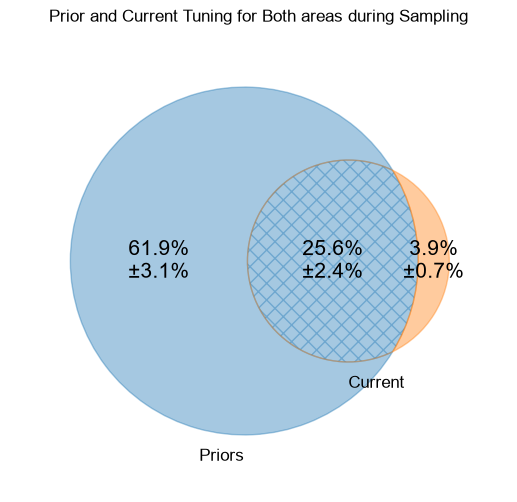

Brain Region: ALM, Priors Tuning: 51.9% ± 4.0%, Current Tuning: 5.9% ± 1.0%, Both Tuned: 32.2% ± 3.6%, No Tuning: 10.0% ± 1.7%
Sizes of combined priors:  84.02653719870462  current:  38.09871685256265  max_combined_ratio:  1.159734628012954


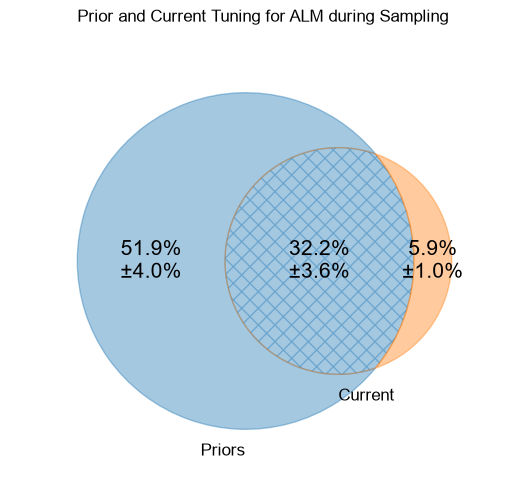

Brain Region: M2, Priors Tuning: 69.7% ± 3.1%, Current Tuning: 2.3% ± 0.7%, Both Tuned: 20.5% ± 2.6%, No Tuning: 7.4% ± 1.6%
Sizes of combined priors:  90.24538596408892  current:  22.86136556227803  max_combined_ratio:  1.097546140359111


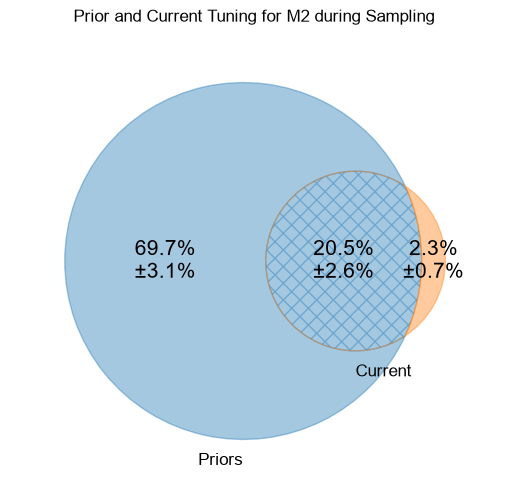

Brain Region: Both areas, Priors Tuning: 21.3% ± 2.2%, Current Tuning: 25.4% ± 1.9%, Both Tuned: 41.4% ± 2.4%, No Tuning: 11.9% ± 1.2%
Sizes of combined priors:  62.67570792243411  current:  66.78320875698053  max_combined_ratio:  1.3321679124301946


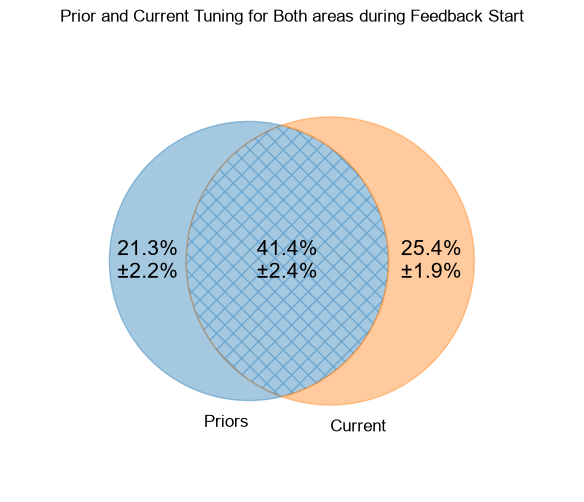

Brain Region: ALM, Priors Tuning: 22.3% ± 4.1%, Current Tuning: 25.3% ± 3.6%, Both Tuned: 38.2% ± 2.4%, No Tuning: 14.3% ± 1.3%
Sizes of combined priors:  60.44467442862203  current:  63.41858517401493  max_combined_ratio:  1.3658141482598507


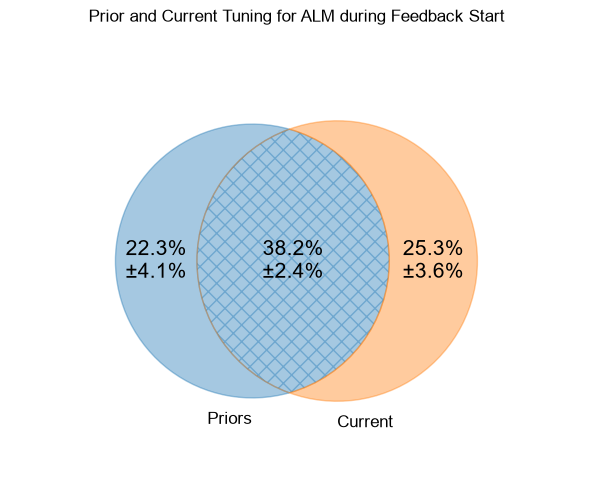

Brain Region: M2, Priors Tuning: 20.5% ± 2.4%, Current Tuning: 25.5% ± 2.2%, Both Tuned: 43.9% ± 3.8%, No Tuning: 10.1% ± 1.7%
Sizes of combined priors:  64.39188753305878  current:  69.37138074387714  max_combined_ratio:  1.3062861925612286


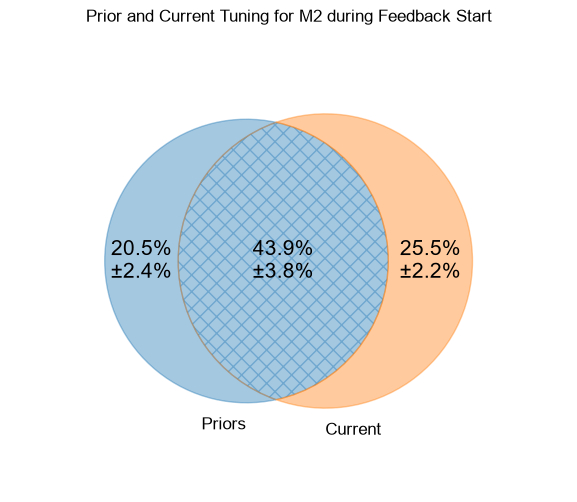

In [ ]:
from .twop.priorcurtuning import plotPriorCurrentTuning

sampling_tuning = plotPriorCurrentTuning(sampling_pref_df, epoch_str="Sampling",
                                         save_figs=SAVE_FIGS, fig_save_prefix=fig_save_prefix)
feedback_tuning = plotPriorCurrentTuning(feedback_pref_df, epoch_str="Feedback Start",
                                         save_figs=SAVE_FIGS, fig_save_prefix=fig_save_prefix)